# 2

### Nota: 9.63

Este ejercicio consiste en construir una red neuronal en PyTorch que realice la clasificación binaria para predecir si una persona tiene diabetes, usando el dataset 'Pima Indians Diabetes Database'. La columna “Outcome” será el objetivo, con valores 0 (no tiene diabetes) o 1 (tiene diabetes).

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk
import torch
import torch.nn as nn

work_dir = "../media/2_lab1/2/"
file_dir = "diabetes.csv"
seed = 112211

In [96]:
data = pd.read_csv(work_dir + file_dir)
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Las características consisten en ciertos parámetros de salud, todos numéricos. La variable a predecir es binaria → 0 : no diabetes, 1 : diabetes

In [97]:
data.shape[0]

768

In [98]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


No hay valores nulos, pero hay valores con valor 0, lo cuál no es posible en ninguna de las variables a predecir menos la de embarazo. Por lo que rellenamos los valores con 0 con la mediana

In [99]:
transformable = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"] 
data[transformable] = data[transformable].replace(0, np.nan)
data[transformable] = data[transformable].fillna(data[transformable].median())

Separamos los features del target, normalizamos los features para que tengan un rango comparable, y hacemos la separación de entrenamiento y test.

In [100]:
from sklearn.model_selection import train_test_split
norm = lambda x: (x - x.min()) / (x.max() - x.min())

X = data.drop(columns = "Outcome").apply(norm)
y = data["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = seed)

Comprobemos que efectivamente X se ha normalizado

In [101]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,0.226180,0.198210,0.0,0.058824,0.176471,0.352941,1.0
Glucose,768.0,0.501008,0.196376,0.0,0.359677,0.470968,0.620968,1.0
BloodPressure,768.0,0.493742,0.123435,0.0,0.408163,0.489796,0.571429,1.0
SkinThickness,768.0,0.240305,0.095557,0.0,0.195652,0.239130,0.271739,1.0
Insulin,768.0,0.152250,0.103826,0.0,0.129207,0.133413,0.136118,1.0
BMI,768.0,0.291518,0.140597,0.0,0.190184,0.288344,0.376278,1.0
DiabetesPedigreeFunction,768.0,0.168179,0.141473,0.0,0.070773,0.125747,0.234095,1.0
Age,768.0,0.204015,0.196004,0.0,0.050000,0.133333,0.333333,1.0


Convertimos en tensores compatibles con la red que vamos a construir.

In [102]:
X_train = torch.from_numpy(X_train.to_numpy(dtype=np.float32))
X_test = torch.from_numpy(X_test.to_numpy(dtype=np.float32))
y_train = torch.from_numpy(y_train.to_numpy(dtype=np.float32)).reshape(-1, 1)
y_test = torch.from_numpy(y_test.to_numpy(dtype=np.float32)).reshape(-1, 1)

Veamos con lo que se está trabajando.

In [103]:
print(X_train)
print(X_train.shape)
print(X_test)
print(X_test.shape)
print(y_train)
print(y_train.shape)
print(y_test)
print(y_test.shape)

tensor([[0.1765, 0.8774, 0.4082,  ..., 0.3231, 0.0824, 0.0833],
        [0.5882, 0.7613, 0.6122,  ..., 0.1943, 0.0444, 0.5500],
        [0.0000, 0.8581, 0.3673,  ..., 0.3354, 0.4244, 0.0000],
        ...,
        [0.2353, 0.6581, 0.5510,  ..., 0.4151, 0.1887, 0.7667],
        [0.2353, 0.3290, 0.4694,  ..., 0.2843, 0.2280, 0.0500],
        [0.2353, 0.9355, 0.8776,  ..., 0.2106, 0.2570, 0.2667]])
torch.Size([576, 8])
tensor([[0.6471, 0.3806, 0.4490,  ..., 0.5726, 0.0205, 0.3500],
        [0.1765, 0.8065, 0.5102,  ..., 0.2393, 0.0811, 0.1667],
        [0.4706, 0.9290, 0.5510,  ..., 0.6074, 0.0252, 0.3667],
        ...,
        [0.2941, 0.2129, 0.5918,  ..., 0.3599, 0.0333, 0.2333],
        [0.3529, 0.3032, 0.4898,  ..., 0.2372, 0.1806, 0.1667],
        [0.2353, 0.4516, 0.4082,  ..., 0.2188, 0.0205, 0.0500]])
torch.Size([192, 8])
tensor([[0.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        

Construimos la red

In [104]:
class ffnet(nn.Module):
    def __init__(
            self,
            input_size: int,
            output_size: int
    ):       
        super().__init__()
        self.h1 = nn.Linear(input_size, 64)
        self.relu1 = nn.ReLU()
        self.h2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.out = nn.Linear(32, output_size)
        self.sigmoid = nn.Sigmoid()


    def forward(
            self,
            x
    ):
        x = self.h1(x)
        x = self.relu1(x)
        x = self.h2(x)
        x = self.relu2(x)
        x = self.out(x)
        return self.sigmoid(x)

Pasemos al entrenamiento. Usaremos como función de pérdida la entropía cruzada binaria, y un optimizador Adam con $\alpha = 0.001$ Probamos con 200 epochs.

In [105]:
model = ffnet(X.shape[1], 1)

epochs = 200
lr = 0.001
loss = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr = lr)

hist = []
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    pred = model(X_train)
    l = loss(pred, y_train)
    l.backward()
    optimizer.step()
    hist.append(l.detach().numpy())
    if (epoch + 1)%10 == 0: print(f"Epoch {epoch + 1} finalizado -> Binary Cross-Entropy : {l}")

Epoch 10 finalizado -> Binary Cross-Entropy : 0.6746885776519775
Epoch 20 finalizado -> Binary Cross-Entropy : 0.6635472178459167
Epoch 30 finalizado -> Binary Cross-Entropy : 0.6526401042938232
Epoch 40 finalizado -> Binary Cross-Entropy : 0.6404860019683838
Epoch 50 finalizado -> Binary Cross-Entropy : 0.6268265247344971
Epoch 60 finalizado -> Binary Cross-Entropy : 0.6104204654693604
Epoch 70 finalizado -> Binary Cross-Entropy : 0.590099036693573
Epoch 80 finalizado -> Binary Cross-Entropy : 0.5660465359687805
Epoch 90 finalizado -> Binary Cross-Entropy : 0.539832353591919
Epoch 100 finalizado -> Binary Cross-Entropy : 0.5148006081581116
Epoch 110 finalizado -> Binary Cross-Entropy : 0.493097722530365
Epoch 120 finalizado -> Binary Cross-Entropy : 0.47654321789741516
Epoch 130 finalizado -> Binary Cross-Entropy : 0.4649864733219147
Epoch 140 finalizado -> Binary Cross-Entropy : 0.4572181701660156
Epoch 150 finalizado -> Binary Cross-Entropy : 0.45205825567245483
Epoch 160 finalizado

Veamos cómo ha evolucionado la función de pérdida

Text(0, 0.5, 'BCE')

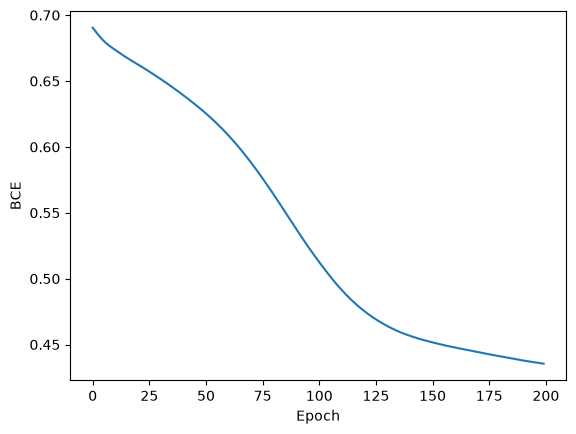

In [106]:
plt.plot(hist)
plt.xlabel("Epoch")
plt.ylabel("BCE")

Vamos a usar un umbral del 0.5. Valores de la predicción que queden por arriba se les considera 1 (diabetes), y a los demás 0 (no tiene diabetes)

In [107]:
y_pred = model(X_test).detach().numpy()
y_pred = np.array([1 if y >= 0.5 else 0 for y in y_pred])
y_test = y_test.detach().numpy()

Mediante la accuracy, el f1 score y el classification report podemos evaluar el rendimiento del modelo.

In [108]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
rep = classification_report(y_test, y_pred)

print(f"Accuracy: {acc}")
print(f"F1 Score: {f1}")
print(f"Classification Report: \n{rep}")

Accuracy: 0.7552083333333334
F1 Score: 0.5688073394495413
Classification Report: 
              precision    recall  f1-score   support

         0.0       0.77      0.90      0.83       126
         1.0       0.72      0.47      0.57        66

    accuracy                           0.76       192
   macro avg       0.74      0.69      0.70       192
weighted avg       0.75      0.76      0.74       192

